# ESMFold v1 — Low-complexity sequence fraction


## 1. Data source/acquisition

Download the public analysis package, including320 query sequences, experimental C-alpha coordinates with residue-index mappings, ESMFold v1 predictions and individual template-reference measurements. The panel uses X-ray PDB chains released2023-01-01 through2024-06-30, resolution≤3Å, length40–400 and resolved fraction≥0.70, with30%-identity deduplication.


In [1]:
from pathlib import Path
import os,json,hashlib,zipfile,urllib.request,io,socket
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display,Image
from Bio.SeqUtils import seq1
from tmtools import tm_align
DATA_ROOT=Path(os.environ.get('ESMFOLD_RELEASE_ROOT',str(Path.cwd()/'released-inputs')))
CALC_ROOT=Path(os.environ.get('ESMFOLD_CALC_ROOT',str(Path.cwd()/'calculations')))/'kimi-r1'
DATA_ROOT.mkdir(parents=True,exist_ok=True)
def sha256_file(path):
    digest=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(1024*1024),b''):digest.update(block)
    return digest.hexdigest()
archive=DATA_ROOT/'esmfold2-inputs.zip'
source_url='https://github.com/shreyjain11/SPECTRAagent/releases/download/notebook-inputs-2026-11-08-v1/esmfold2-inputs.zip'
source_sha='c0c76766965d90de4128d0d3e11abadcf39f4acac8cff64c374657ee77172b24'
if not archive.is_file() or sha256_file(archive)!=source_sha:
    temporary=archive.with_suffix('.download')
    urllib.request.urlretrieve(source_url,temporary)
    if sha256_file(temporary)!=source_sha:raise ValueError('Public input archive fingerprint differs')
    temporary.replace(archive)
with zipfile.ZipFile(archive) as bundle:
    members=[m for m in bundle.infolist() if m.filename.startswith('assets/kimi-r1/') and not m.is_dir() and not m.filename.endswith('.py')]
    for item in members:
        destination=(DATA_ROOT/item.filename).resolve()
        if DATA_ROOT.resolve() not in destination.parents:raise ValueError('Invalid archive member path')
        destination.parent.mkdir(parents=True,exist_ok=True)
        payload=bundle.read(item)
        if not destination.exists() or hashlib.sha256(destination.read_bytes()).digest()!=hashlib.sha256(payload).digest():destination.write_bytes(payload)
P=DATA_ROOT/'assets/kimi-r1'
print('Verified public input archive:',source_url,'SHA256',source_sha)
print('Acquired data files:',len(members))


Verified public input archive: https://github.com/shreyjain11/SPECTRAagent/releases/download/notebook-inputs-2026-11-08-v1/esmfold2-inputs.zip SHA256 c0c76766965d90de4128d0d3e11abadcf39f4acac8cff64c374657ee77172b24
Acquired data files: 1508


## 2. Data processing

Read the full query sequence and experimental residue-index mapping for each chain. Validate coordinate lengths and mapping bounds. Compute sequence length and resolved fraction directly from these arrays.


In [2]:
plan=pd.read_csv(P/'results/panel_final.tsv',sep='\t',usecols=['rep'])
if plan.rep.duplicated().any():raise ValueError('Duplicate protein-chain IDs')
native_arrays={};rows=[]
for rep in plan.rep:
    path=P/'results/native'/f'{rep}.npz'
    with np.load(path) as source:
        sequence=str(source['seq']);indices=source['res_idx'].copy();coordinates=source['ca'].copy()
    if len(indices)!=len(coordinates) or len(indices)==0:raise ValueError('Invalid experimental residue mapping: '+rep)
    if indices.min()<0 or indices.max()>=len(sequence):raise ValueError('Experimental mapping lies outside the query')
    native_arrays[rep]=(sequence,indices,coordinates)
    rows.append({'rep':rep,'sequence':sequence,'sequence_length':len(sequence),'observed_residues':len(indices),'resolved_fraction':len(indices)/len(sequence),'native_sha256':sha256_file(path)})
features=pd.DataFrame(rows)
print('Processed full query sequences and experimental residue mappings:',len(features))
display(features[['rep','sequence_length','observed_residues','resolved_fraction']])


Processed full query sequences and experimental residue mappings: 320


,rep,sequence_length,observed_residues,resolved_fraction
0,7SC4_A,130,111,0.853846
1,8BJP_AAA,112,109,0.973214
2,8BZN_A,125,124,0.992000
3,8DZ8_A,101,97,0.960396
4,8D51_A,103,99,0.961165
...,...,...,...,...
315,8T19_A,86,86,1.000000
316,7YHR_A,60,59,0.983333
317,8EB5_A,78,74,0.948718
318,8OKS_B,118,111,0.940678


## 3. Axis definition and level construction

Scan12-residue windows; mark every residue in a window with Shannon entropy<2.2 bits and merge overlapping marks. The axis is the fraction marked. Levels are<5%,5–10%,10–20% and≥20%.


In [3]:
import math, random
from collections import defaultdict

def lc_fraction(seq, win=12, thr=2.2):
    n = len(seq)
    if n < win:
        return 0.0
    mask = [0] * n
    for i in range(n - win + 1):
        w = seq[i:i + win]
        from collections import Counter
        c = Counter(w)
        H = -sum((v / win * math.log2(v / win) for v in c.values()))
        if H < thr:
            for j in range(i, i + win):
                mask[j] = 1
    return sum(mask) / n

def level_b(f):
    if f < 0.05:
        return 'B1'
    if f < 0.1:
        return 'B2'
    if f < 0.2:
        return 'B3'
    return 'B4'
features['low_complexity_fraction']=features.sequence.map(lc_fraction)
features['level']=features.low_complexity_fraction.map(level_b)
features['length_bin']=pd.cut(features.sequence_length,[39,149,249,400],labels=['40–149','150–249','250–400'])
LEVELS=['B1','B2','B3','B4']
display(features[['rep','low_complexity_fraction','level','length_bin']])
display(features.groupby('level').agg(n=('rep','size'),fraction_min=('low_complexity_fraction','min'),fraction_mean=('low_complexity_fraction','mean'),fraction_max=('low_complexity_fraction','max')))


,rep,low_complexity_fraction,level,length_bin
0,7SC4_A,0.261538,B4,40–149
1,8BJP_AAA,0.000000,B1,40–149
2,8BZN_A,0.000000,B1,40–149
3,8DZ8_A,0.000000,B1,40–149
4,8D51_A,0.000000,B1,40–149
...,...,...,...,...
315,8T19_A,0.139535,B3,40–149
316,7YHR_A,0.000000,B1,40–149
317,8EB5_A,0.000000,B1,40–149
318,8OKS_B,0.101695,B3,40–149


,n,fraction_min,fraction_mean,fraction_max
level,,,,
B1,203,0.000000,0.006097,0.048387
B2,50,0.051546,0.075106,0.097561
B3,51,0.100719,0.143552,0.198068
B4,16,0.206897,0.312195,0.549587


## 4. Model results or released scores

Calculate TM-score, GDT-TS, GDT-HA and RMSD from released ESMFold v1 predictions using the experimental residue mapping. The weighted superposition uses10 iterations and normalization by resolved reference length. Template-reference scores are individual released measurements. The visible inference function takes an initialized fair-esm ESMFold v1 model; this notebook evaluates the released model coordinates.


In [4]:
import numpy as np

def kabsch(P, Q, w=None):
    if w is None:
        w = np.ones(len(P))
    w = w / w.sum()
    cp = (P * w[:, None]).sum(0)
    cq = (Q * w[:, None]).sum(0)
    Pc = P - cp
    Qc = Q - cq
    H = (Pc * w[:, None]).T @ Qc
    U, S, Vt = np.linalg.svd(H)
    d = np.sign(np.linalg.det(Vt.T @ U.T))
    D = np.diag([1.0, 1.0, d])
    R = Vt.T @ D @ U.T
    return (R, cq - R @ cp)

def tm_gdt(P, Q, Lnorm):
    d0 = 1.24 * (max(Lnorm, 17) - 15) ** (1.0 / 3.0) - 1.8
    d0 = max(d0, 0.5)
    w = np.ones(len(P))
    for _ in range(10):
        R, t = kabsch(P, Q, w)
        d = np.linalg.norm(P @ R.T + t - Q, axis=1)
        w_new = 1.0 / (1.0 + (d / d0) ** 2)
        if np.allclose(w_new, w, atol=1e-06):
            w = w_new
            break
        w = w_new
    tm = float(np.mean(1.0 / (1.0 + (d / d0) ** 2))) * len(P) / Lnorm
    gdt_ts = float(np.mean([np.mean(d <= c) for c in (1, 2, 4, 8)])) * len(P) / Lnorm
    gdt_ha = float(np.mean([np.mean(d <= c) for c in (0.5, 1, 2, 4)])) * len(P) / Lnorm
    rmsd = float(np.sqrt(np.mean(d ** 2)))
    return (tm, gdt_ts, gdt_ha, rmsd)

def pred_ca(pdbpath):
    coords = []
    for line in open(pdbpath):
        if line.startswith('ATOM') and line[12:16].strip() == 'CA':
            coords.append([float(line[30:38]), float(line[38:46]), float(line[46:54])])
    return np.array(coords, dtype=np.float32)

def predict_structure(sequence,model,seed=0):
    import torch
    torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
    with torch.no_grad():return model.infer_pdb(sequence)

score_rows=[]
for rep in features.rep:
    sequence,indices,native=native_arrays[rep]
    predicted=pred_ca(P/'results/pred'/f'{rep}.pdb')
    if len(predicted)!=len(sequence):raise ValueError('Prediction length does not match input sequence: '+rep)
    tm,gdt_ts,gdt_ha,rmsd=tm_gdt(predicted[indices],native,len(indices))
    score_rows.append({'rep':rep,'tm_model':float(f'{tm:.4f}'),'gdt_ts':float(f'{gdt_ts:.4f}'),'gdt_ha':float(f'{gdt_ha:.4f}'),'rmsd':float(f'{rmsd:.2f}')})
reference=pd.read_csv(P/'results/baseline_scores.tsv',sep='\t',usecols=['rep','baseline_tm','n_pairs','qcov'])
reference=reference.rename(columns={'baseline_tm':'tm_reference','n_pairs':'reference_pairs','qcov':'reference_query_coverage'})
measurements=features.merge(pd.DataFrame(score_rows),on='rep',validate='one_to_one').merge(reference,on='rep',how='left',validate='one_to_one')
if not np.isfinite(measurements.tm_model).all():raise ValueError('Incomplete target-model scores')
display(measurements[['rep','level','tm_model','gdt_ts','rmsd','tm_reference']])


,rep,level,tm_model,gdt_ts,rmsd,tm_reference
0,7SC4_A,B4,0.8530,0.8446,3.14,0.6995
1,8BJP_AAA,B1,0.9654,0.9656,0.76,0.8929
2,8BZN_A,B1,0.1725,0.0907,18.28,0.8714
3,8DZ8_A,B1,0.8349,0.8015,2.24,0.8362
4,8D51_A,B1,0.9077,0.8889,1.64,0.9471
...,...,...,...,...,...,...
315,8T19_A,B3,0.9407,0.9273,0.87,NaN
316,7YHR_A,B1,0.6179,0.6483,4.21,NaN
317,8EB5_A,B1,0.9076,0.9223,1.56,NaN
318,8OKS_B,B3,0.9371,0.9324,1.54,NaN


## 5. Curves and controls

Calculate means and95% Student-t intervals, with explicit per-level counts. Inspect resolved fraction, template coverage and the three length strata. The low-complexity axis is exploratory if any level has fewer than40 targets.


,level,model,n,mean,lo,hi
0,B1,ESMFold v1,203,0.856033,0.828972,0.883094
1,B1,Template reference,160,0.809296,0.782067,0.836525
2,B2,ESMFold v1,50,0.846586,0.785109,0.908063
3,B2,Template reference,43,0.818184,0.755300,0.881068
4,B3,ESMFold v1,51,0.870051,0.821216,0.918886
5,B3,Template reference,36,0.738367,0.662506,0.814227
6,B4,ESMFold v1,16,0.906994,0.840955,0.973032
7,B4,Template reference,10,0.691620,0.535800,0.847440


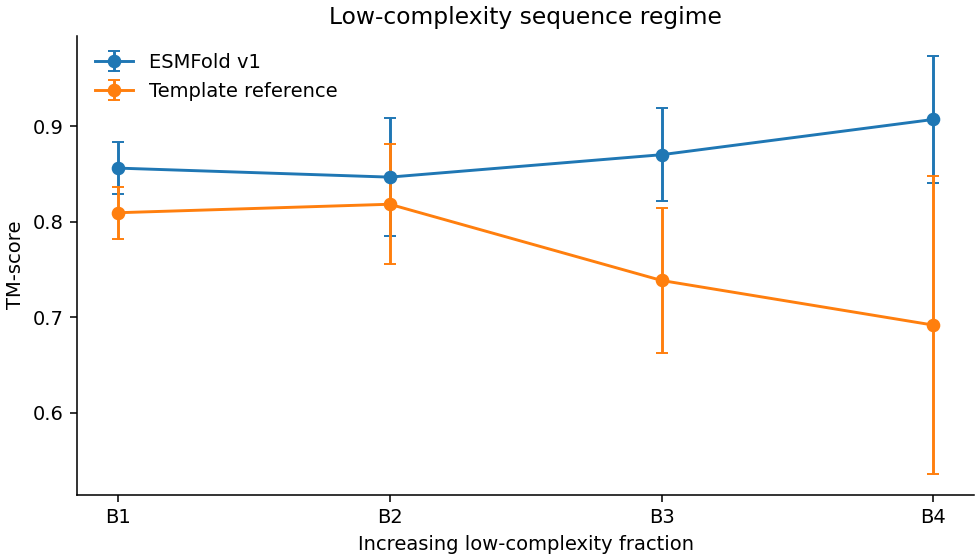

,n,length_mean,resolved_fraction_mean,low_complexity_mean,gdt_ts_mean,reference_covered
level,,,,,,
B1,203,209.300493,0.942938,0.006097,0.800804,160
B2,50,225.460000,0.911031,0.075106,0.771394,43
B3,51,170.882353,0.902136,0.143552,0.820061,36
B4,16,146.000000,0.909258,0.312195,0.890956,10


,level,length_bin,n,model_mean,reference_mean
0,B1,40–149,77,0.828621,0.790073
1,B1,150–249,55,0.866876,0.825775
2,B1,250–400,71,0.877362,0.817084
3,B2,40–149,8,0.917550,0.879217
4,B2,150–249,27,0.862796,0.781608
5,B2,250–400,15,0.779560,0.863867
6,B3,40–149,30,0.879490,0.671990
7,B3,150–249,13,0.830038,0.841812
8,B3,250–400,8,0.899675,0.819271
9,B4,40–149,9,0.860444,0.660757


In [5]:
def mean_curve(frame,column='level'):
    rows=[]
    for level,group in frame.groupby(column,observed=True):
        for label,metric in [('ESMFold v1','tm_model'),('Template reference','tm_reference')]:
            values=group[metric].dropna().to_numpy(float);n=len(values)
            if n==0:continue
            mean=float(values.mean());half=float(stats.t.ppf(.975,n-1)*stats.sem(values)) if n>1 else np.nan
            rows.append({'level':str(level),'model':label,'n':n,'mean':mean,'lo':mean-half,'hi':mean+half})
    return pd.DataFrame(rows)
curve=mean_curve(measurements)
display(curve)
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
for label,group in curve.groupby('model',sort=False):
    ax.errorbar(group.level,group['mean'],yerr=[group['mean']-group.lo,group.hi-group['mean']],marker='o',capsize=3,label=label)
ax.set(xlabel='Increasing low-complexity fraction',ylabel='TM-score',title='Low-complexity sequence regime');ax.legend(frameon=False);ax.spines[['top','right']].set_visible(False)
buffer=io.BytesIO();fig.savefig(buffer,format='png',dpi=140);plt.close(fig);display(Image(data=buffer.getvalue()))
confound_table=measurements.groupby('level').agg(n=('rep','size'),length_mean=('sequence_length','mean'),resolved_fraction_mean=('resolved_fraction','mean'),low_complexity_mean=('low_complexity_fraction','mean'),gdt_ts_mean=('gdt_ts','mean'),reference_covered=('tm_reference','count'))
length_strata=measurements.groupby(['level','length_bin'],observed=True).agg(n=('rep','size'),model_mean=('tm_model','mean'),reference_mean=('tm_reference','mean')).reset_index()
display(confound_table);display(length_strata)


## 6. What the agent decided, and why

Use the calculated counts, curve direction and endpoint contrast to determine the supported conclusion.


In [6]:
counts=features.groupby('level').size().reindex(LEVELS,fill_value=0)
adequate=bool(counts.ge(40).all())
means=measurements.groupby('level').tm_model.mean().reindex(LEVELS)
monotone=bool(means.notna().all() and np.all(np.diff(means.to_numpy())<0))
contrast=float(means.iloc[0]-means.iloc[-1])
if not adequate:decision='Keep the low-complexity axis exploratory: at least one level contains fewer than40 targets.'
elif not monotone or contrast<.15:decision='The level means do not meet the monotone decline and0.15 endpoint-effect requirements.'
else:decision='The means meet the directional and effect-size requirements; a confirmatory trend test remains necessary.'
print(decision)
print('Counts by level:',counts.to_dict());print('Strictly decreasing means:',monotone,'; B1-minus-B4 TM-score:',contrast)
output=CALC_ROOT/'test-03';output.mkdir(parents=True,exist_ok=True)
features.to_csv(output/'axis_levels.csv',index=False);measurements.to_csv(output/'coordinate_scores.csv',index=False);curve.to_csv(output/'curves.csv',index=False);confound_table.to_csv(output/'confounds.csv');length_strata.to_csv(output/'length_controls.csv',index=False)
receipt={'analysis_id':'esmfold2-kimi-r1/test-03','completed':True,'host':socket.gethostname(),'input_archive_url':source_url,'input_archive_sha256':source_sha,'targets':len(features),'new_inference_executed':False,'calculation_scope':'full-sequence low-complexity calculation, coordinate scoring, per-target template-score join, curves, controls and decision','decision':decision}
(output/'CALCULATION_RECEIPT.json').write_text(json.dumps(receipt,indent=2))


Keep the low-complexity axis exploratory: at least one level contains fewer than40 targets.
Counts by level: {'B1': 203, 'B2': 50, 'B3': 51, 'B4': 16}
Strictly decreasing means: False ; B1-minus-B4 TM-score: -0.0509607450738917


653